In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from google.colab import files

uploaded = files.upload()

Saving archive(7).zip to archive(7).zip


In [4]:
import zipfile

with zipfile.ZipFile('archive(7).zip', 'r') as zip_ref:
    zip_ref.extract('DataCoSupplyChainDataset.csv')

In [5]:
df = pd.read_csv(
    'DataCoSupplyChainDataset.csv',
    encoding='latin1'
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [8]:
df.isnull().sum().sort_values(ascending=False).head(15)

,0
Product Description,180519
Order Zipcode,155679
Customer Lname,8
Customer Zipcode,3
Days for shipment (scheduled),0
Sales per customer,0
Benefit per order,0
Delivery Status,0
Late_delivery_risk,0
Customer City,0


In [9]:
# Remove columns with excessive missing values
columns_to_drop = [
    'Product Description',
    'Order Zipcode',
    'Customer Lname',
    'Customer Zipcode'
]

df = df.drop(columns=columns_to_drop)

# Check missing values again
print("Remaining missing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nUpdated dataset shape:", df.shape)

Remaining missing values:
Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Benefit per order                0
Sales per customer               0
Delivery Status                  0
Late_delivery_risk               0
Category Id                      0
Category Name                    0
Customer City                    0
dtype: int64

Updated dataset shape: (180519, 49)


In [10]:
print(df['Late_delivery_risk'].value_counts())

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64


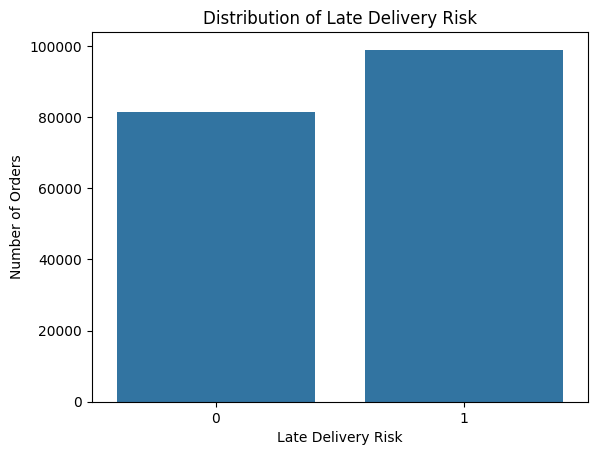

In [11]:
sns.countplot(data=df, x='Late_delivery_risk')

plt.title('Distribution of Late Delivery Risk')
plt.xlabel('Late Delivery Risk')
plt.ylabel('Number of Orders')
plt.show()

In [12]:
# Display all column names
for i, col in enumerate(df.columns):
    print(i+1, col)

1 Type
2 Days for shipping (real)
3 Days for shipment (scheduled)
4 Benefit per order
5 Sales per customer
6 Delivery Status
7 Late_delivery_risk
8 Category Id
9 Category Name
10 Customer City
11 Customer Country
12 Customer Email
13 Customer Fname
14 Customer Id
15 Customer Password
16 Customer Segment
17 Customer State
18 Customer Street
19 Department Id
20 Department Name
21 Latitude
22 Longitude
23 Market
24 Order City
25 Order Country
26 Order Customer Id
27 order date (DateOrders)
28 Order Id
29 Order Item Cardprod Id
30 Order Item Discount
31 Order Item Discount Rate
32 Order Item Id
33 Order Item Product Price
34 Order Item Profit Ratio
35 Order Item Quantity
36 Sales
37 Order Item Total
38 Order Profit Per Order
39 Order Region
40 Order State
41 Order Status
42 Product Card Id
43 Product Category Id
44 Product Image
45 Product Name
46 Product Price
47 Product Status
48 shipping date (DateOrders)
49 Shipping Mode


In [13]:
print(df['Late_delivery_risk'].value_counts())

print("\nPercentage distribution:")
print(df['Late_delivery_risk'].value_counts(normalize=True) * 100)

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Percentage distribution:
Late_delivery_risk
1    54.829132
0    45.170868
Name: proportion, dtype: float64


In [14]:
df.dtypes

,0
Type,object
Days for shipping (real),int64
Days for shipment (scheduled),int64
Benefit per order,float64
Sales per customer,float64
Delivery Status,object
Late_delivery_risk,int64
Category Id,int64
Category Name,object
Customer City,object


In [15]:
# Define target variable
target = 'Late_delivery_risk'

# Numerical features
numerical_features = [
    'Sales per customer',
    'Benefit per order',
    'Order Item Quantity',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Product Price',
    'Order Item Total'
]

# Categorical features
categorical_features = [
    'Type',
    'Shipping Mode',
    'Customer Segment',
    'Market',
    'Category Name',
    'Department Name',
    'Order Region'
]

# Text feature for embeddings
text_features = ['Product Name']

# Check whether all selected columns exist
selected_features = (
    numerical_features +
    categorical_features +
    text_features
)

print("Available features:")
print([col for col in selected_features if col in df.columns])

print("\nMissing feature names:")
print([col for col in selected_features if col not in df.columns])

Available features:
['Sales per customer', 'Benefit per order', 'Order Item Quantity', 'Order Item Discount', 'Order Item Discount Rate', 'Product Price', 'Order Item Total', 'Type', 'Shipping Mode', 'Customer Segment', 'Market', 'Category Name', 'Department Name', 'Order Region', 'Product Name']

Missing feature names:
[]


In [16]:
print(df['Late_delivery_risk'].value_counts())

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64


In [17]:
from sklearn.model_selection import train_test_split

# Input features
X = df[numerical_features + categorical_features + text_features]

# Target variable
y = df['Late_delivery_risk']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training data shape: (144415, 15)
Testing data shape: (36104, 15)

Training target distribution:
Late_delivery_risk
1    0.548288
0    0.451712
Name: proportion, dtype: float64

Testing target distribution:
Late_delivery_risk
1    0.548305
0    0.451695
Name: proportion, dtype: float64


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

In [19]:
from sklearn.tree import DecisionTreeClassifier

# Create model
baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])

# Train model
baseline_model.fit(
    X_train[numerical_features + categorical_features],
    y_train
)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Predict on test data
y_pred = baseline_model.predict(
    X_test[numerical_features + categorical_features]
)

# Calculate performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6931918900952803
Precision: 0.8345997390436718
Recall: 0.5493028894726207
F1 Score: 0.6625437928408225

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.87      0.72     16308
           1       0.83      0.55      0.66     19796

    accuracy                           0.69     36104
   macro avg       0.72      0.71      0.69     36104
weighted avg       0.73      0.69      0.69     36104



In [21]:
!pip install -q sentence-transformers

In [22]:
from sentence_transformers import SentenceTransformer

# Load pretrained model
embedding_model = SentenceTransformer('all-MiniLM-L6-v2')

print("Embedding model loaded successfully!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded successfully!


In [23]:
import numpy as np

# Get unique product names
unique_products = df['Product Name'].fillna('Unknown').astype(str).unique()

print("Number of unique products:", len(unique_products))

# Generate embeddings
product_embeddings = embedding_model.encode(
    unique_products,
    show_progress_bar=True
)

print("Embedding shape:", product_embeddings.shape)

Number of unique products: 118


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Embedding shape: (118, 384)


In [24]:
# Create product-to-embedding mapping
embedding_dict = dict(zip(unique_products, product_embeddings))

# Convert training product names into embeddings
X_train_text = np.vstack([
    embedding_dict[p]
    for p in X_train['Product Name'].fillna('Unknown').astype(str)
])

# Convert testing product names into embeddings
X_test_text = np.vstack([
    embedding_dict[p]
    for p in X_test['Product Name'].fillna('Unknown').astype(str)
])

print("Training embeddings:", X_train_text.shape)
print("Testing embeddings:", X_test_text.shape)

Training embeddings: (144415, 384)
Testing embeddings: (36104, 384)


In [25]:
# Create embedding dictionary
embedding_dict = dict(zip(unique_products, product_embeddings))

# Generate training embeddings
X_train_text = np.vstack([
    embedding_dict[p]
    for p in X_train['Product Name'].fillna('Unknown').astype(str)
])

# Generate testing embeddings
X_test_text = np.vstack([
    embedding_dict[p]
    for p in X_test['Product Name'].fillna('Unknown').astype(str)
])

print("Training embeddings:", X_train_text.shape)
print("Testing embeddings:", X_test_text.shape)

Training embeddings: (144415, 384)
Testing embeddings: (36104, 384)


In [26]:
from scipy.sparse import hstack, csr_matrix

# Transform traditional features
X_train_traditional = baseline_model.named_steps['preprocessor'].transform(
    X_train[numerical_features + categorical_features]
)

X_test_traditional = baseline_model.named_steps['preprocessor'].transform(
    X_test[numerical_features + categorical_features]
)

# Combine traditional features with text embeddings
X_train_hybrid = hstack([
    X_train_traditional,
    csr_matrix(X_train_text)
]).tocsr()

X_test_hybrid = hstack([
    X_test_traditional,
    csr_matrix(X_test_text)
]).tocsr()

print("Hybrid training shape:", X_train_hybrid.shape)
print("Hybrid testing shape:", X_test_hybrid.shape)

Hybrid training shape: (144415, 491)
Hybrid testing shape: (36104, 491)


In [27]:
from sklearn.tree import DecisionTreeClassifier

hybrid_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

hybrid_model.fit(X_train_hybrid, y_train)

print("Hybrid model trained successfully!")

Hybrid model trained successfully!


In [28]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

y_pred_hybrid = hybrid_model.predict(X_test_hybrid)

print("Hybrid Model Results")
print("--------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_hybrid))
print("Precision:", precision_score(y_test, y_pred_hybrid))
print("Recall:", recall_score(y_test, y_pred_hybrid))
print("F1 Score:", f1_score(y_test, y_pred_hybrid))

Hybrid Model Results
--------------------
Accuracy: 0.6931918900952803
Precision: 0.8337288524841154
Recall: 0.550161648817943
F1 Score: 0.6628929669192611


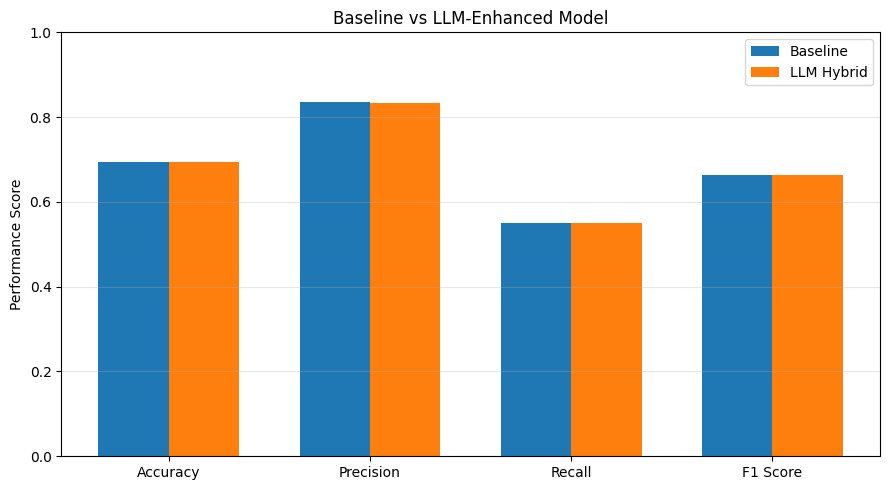

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Define metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

# Model results
baseline = [0.6932, 0.8346, 0.5493, 0.6625]
hybrid = [0.6932, 0.8337, 0.5502, 0.6629]

# Define bar positions
x = np.arange(len(metrics))
width = 0.35

# Create graph
plt.figure(figsize=(9, 5))

plt.bar(x - width/2, baseline, width, label='Baseline')
plt.bar(x + width/2, hybrid, width, label='LLM Hybrid')

plt.xticks(x, metrics)
plt.ylabel('Performance Score')
plt.title('Baseline vs LLM-Enhanced Model')
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

# Save graph
plt.savefig('model_comparison.png', dpi=300)

plt.show()

In [30]:
# Check whether leakage-prone columns are present
leakage_columns = [
    'Days for shipping (real)',
    'Delivery Status',
    'Order Status',
    'shipping date (DateOrders)'
]

used_columns = numerical_features + categorical_features + text_features

print("Leakage check:")

for col in leakage_columns:
    if col in used_columns:
        print(col, "- WARNING: Included")
    else:
        print(col, "- Excluded")

Leakage check:
Days for shipping (real) - Excluded
Delivery Status - Excluded
Order Status - Excluded
shipping date (DateOrders) - Excluded


In [31]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score

# Numerical features
num_features = [
    'Days for shipment (scheduled)',
    'Sales per customer',
    'Benefit per order',
    'Order Item Quantity',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Product Price',
    'Order Item Total'
]

# Categorical features
cat_features = [
    'Type',
    'Shipping Mode',
    'Customer Segment',
    'Market',
    'Category Name',
    'Department Name',
    'Order Region'
]

# Prepare data
X_new = df[num_features + cat_features]
y_new = df['Late_delivery_risk']

# Split data
Xtr, Xte, ytr, yte = train_test_split(
    X_new, y_new,
    test_size=0.20,
    random_state=42,
    stratify=y_new
)

# Preprocessing
prep = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ]), cat_features)
])

# Improved classifier
improved_model = Pipeline([
    ('preprocessor', prep),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=100,
        max_leaf_nodes=31,
        learning_rate=0.1,
        random_state=42
    ))
])

# Train
improved_model.fit(Xtr, ytr)

# Evaluate
pred = improved_model.predict(Xte)

print(classification_report(yte, pred))
print("Improved F1 Score:", f1_score(yte, pred))

              precision    recall  f1-score   support

           0       0.62      0.87      0.72     16308
           1       0.84      0.55      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.71      0.70     36104
weighted avg       0.74      0.70      0.69     36104

Improved F1 Score: 0.6668090950709599


In [32]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)

# 1. Select features
num_features = [
    'Days for shipment (scheduled)',
    'Sales per customer',
    'Benefit per order',
    'Order Item Quantity',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Product Price',
    'Order Item Total'
]

cat_features = [
    'Type',
    'Shipping Mode',
    'Customer Segment',
    'Market',
    'Category Name',
    'Department Name',
    'Order Region'
]

X = df[num_features + cat_features]
y = df['Late_delivery_risk']

# 2. Split into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 3. Split training data for validation
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# 4. Preprocessing
preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ))
    ]), cat_features)
])

# 5. Create model
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=100,
        max_leaf_nodes=31,
        learning_rate=0.1,
        random_state=42
    ))
])

# 6. Train on training subset
print("Training model...")
model.fit(X_fit, y_fit)

# 7. Find optimal threshold using validation data
val_probs = model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, val_probs
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("\nBest threshold:", round(best_threshold, 4))
print("Validation F1:", round(f1_scores[best_index], 4))

# 8. Retrain using complete training data
print("\nRetraining on complete training data...")
model.fit(X_train, y_train)

# 9. Test evaluation
test_probs = model.predict_proba(X_test)[:, 1]
final_pred = (test_probs >= best_threshold).astype(int)

print("\nFINAL MODEL RESULTS")
print("-------------------")
print("Accuracy:", round(accuracy_score(y_test, final_pred), 4))
print("Precision:", round(precision_score(y_test, final_pred), 4))
print("Recall:", round(recall_score(y_test, final_pred), 4))
print("F1 Score:", round(f1_score(y_test, final_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test, final_pred))


Training model...

Best threshold: 0.3694
Validation F1: 0.7159

Retraining on complete training data...

FINAL MODEL RESULTS
-------------------
Accuracy: 0.6025
Precision: 0.5903
Recall: 0.8992
F1 Score: 0.7127

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.24      0.36     16308
           1       0.59      0.90      0.71     19796

    accuracy                           0.60     36104
   macro avg       0.63      0.57      0.53     36104
weighted avg       0.62      0.60      0.55     36104



In [33]:

!pip -q install catboost

import pandas as pd
import numpy as np

from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    precision_recall_curve
)

# 1. Prepare data
data = df.copy()

target = "Late_delivery_risk"

# Features available before or around order placement
numeric_candidates = [
    "Days for shipment (scheduled)",
    "Order Item Quantity",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Product Price",
    "Sales per customer",
    "Order Item Total",
    "Benefit per order",
    "Latitude",
    "Longitude"
]

categorical_candidates = [
    "Type",
    "Shipping Mode",
    "Customer Segment",
    "Market",
    "Order Region",
    "Order Country",
    "Order State",
    "Order City",
    "Customer Country",
    "Customer State",
    "Category Name",
    "Department Name",
    "Product Name"
]

numeric_features = [
    c for c in numeric_candidates if c in data.columns
]

categorical_features = [
    c for c in categorical_candidates if c in data.columns
]

# 2. Create date features from order date
date_col = "order date (DateOrders)"

if date_col in data.columns:
    dates = pd.to_datetime(data[date_col], errors="coerce")
    data["Order_Month"] = dates.dt.month
    data["Order_Day"] = dates.dt.day
    data["Order_Weekday"] = dates.dt.dayofweek

    numeric_features += [
        "Order_Month", "Order_Day", "Order_Weekday"
    ]

# 3. Select features and remove invalid rows
features = numeric_features + categorical_features

X = data[features].copy()
y = data[target].astype(int)

# Convert categorical columns to strings
for col in categorical_features:
    X[col] = X[col].fillna("Unknown").astype(str)

# Replace infinite numerical values
X[numeric_features] = X[numeric_features].replace(
    [np.inf, -np.inf], np.nan
)

# 4. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=42, stratify=y
)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20,
    random_state=42, stratify=y_train
)

cat_indices = [
    X.columns.get_loc(c) for c in categorical_features
]

# 5. Train CatBoost
model = CatBoostClassifier(
    iterations=1200,
    depth=8,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="F1",
    random_seed=42,
    verbose=200,
    early_stopping_rounds=100,
    auto_class_weights="Balanced"
)

print("Training CatBoost...")

model.fit(
    X_fit, y_fit,
    cat_features=cat_indices,
    eval_set=(X_val, y_val),
    use_best_model=True
)

# 6. Find best threshold using validation data
val_probs = model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, val_probs
)

f1_values = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_values)
best_threshold = thresholds[best_idx]

print("\nBest threshold:", round(best_threshold, 4))
print("Validation F1:", round(f1_values[best_idx], 4))

# 7. Evaluate on untouched test data
test_probs = model.predict_proba(X_test)[:, 1]
test_predictions = (test_probs >= best_threshold).astype(int)

print("\nFINAL CATBOOST RESULTS")
print("----------------------")
print("Accuracy:", round(
    accuracy_score(y_test, test_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, test_predictions), 4
))
print("Recall:", round(
    recall_score(y_test, test_predictions), 4
))
print("F1 Score:", round(
    f1_score(y_test, test_predictions), 4
))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

# 8. Feature importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nTOP 15 IMPORTANT FEATURES")
print(importance.head(15).to_string(index=False))


Training CatBoost...
0:	learn: 0.6517714	test: 0.6519275	best: 0.6519275 (0)	total: 658ms	remaining: 13m 8s
200:	learn: 0.8064421	test: 0.8685536	best: 0.8689375 (180)	total: 1m 33s	remaining: 7m 45s
400:	learn: 0.8164859	test: 0.8772082	best: 0.8772903 (396)	total: 3m 22s	remaining: 6m 43s
600:	learn: 0.8243709	test: 0.8813692	best: 0.8814111 (555)	total: 5m 17s	remaining: 5m 16s
800:	learn: 0.8317637	test: 0.8842699	best: 0.8842699 (800)	total: 7m 4s	remaining: 3m 31s
1000:	learn: 0.8385012	test: 0.8862813	best: 0.8862813 (1000)	total: 8m 55s	remaining: 1m 46s
1199:	learn: 0.8456003	test: 0.8889382	best: 0.8891559 (1183)	total: 10m 43s	remaining: 0us

bestTest = 0.8891559286
bestIteration = 1183

Shrink model to first 1184 iterations.

Best threshold: 0.3809
Validation F1: 0.9032

FINAL CATBOOST RESULTS
----------------------
Accuracy: 0.8911
Precision: 0.8939
Recall: 0.9093
F1 Score: 0.9016

Classification Report:
              precision    recall  f1-score   support

           0  

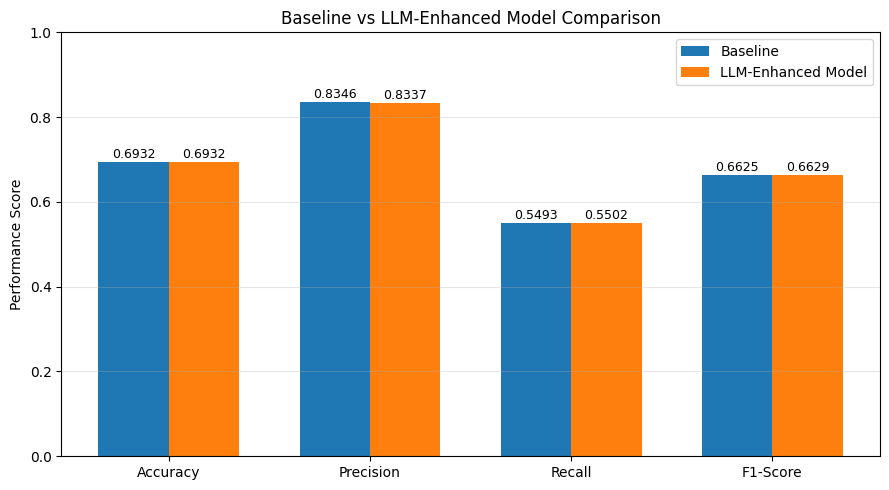

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Evaluation metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

# Experimental results
baseline = [0.6932, 0.8346, 0.5493, 0.6625]
llm_hybrid = [0.6932, 0.8337, 0.5502, 0.6629]

# Bar chart
x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

bars1 = plt.bar(x - width/2, baseline, width, label='Baseline')
bars2 = plt.bar(x + width/2, llm_hybrid, width, label='LLM-Enhanced Model')

# Labels and title
plt.title('Baseline vs LLM-Enhanced Model Comparison')
plt.ylabel('Performance Score')
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

# Display values
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.01,
            f'{height:.4f}',
            ha='center',
            fontsize=9
        )

plt.tight_layout()

# Save high-resolution graph
plt.savefig('Baseline_vs_LLM_Comparison.png', dpi=300, bbox_inches='tight')

plt.show()

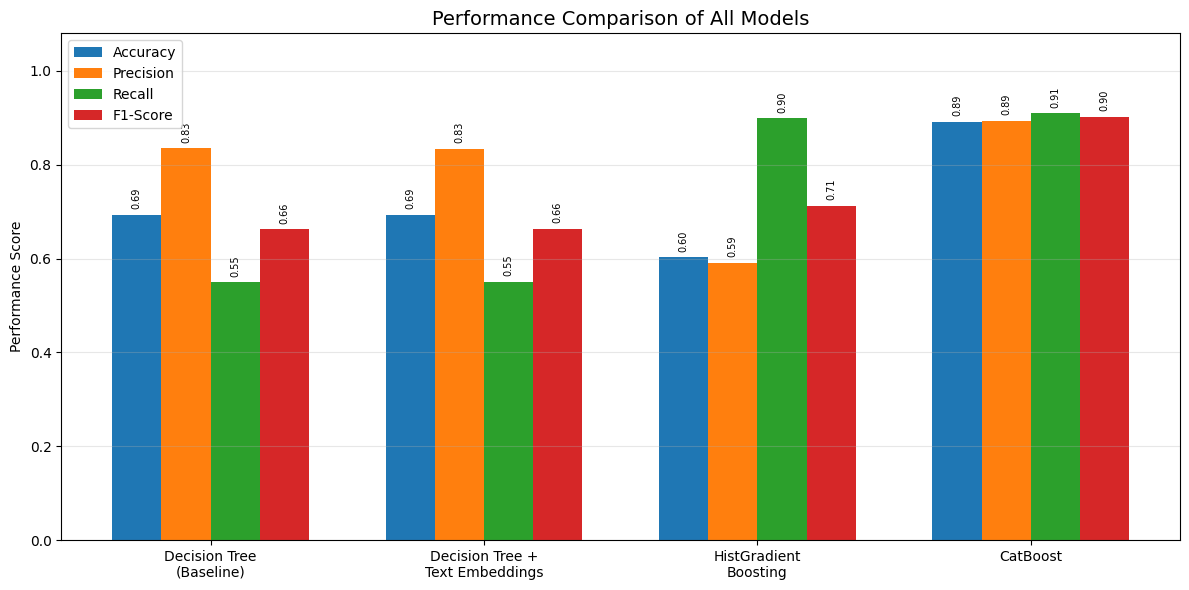

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Model names
models = [
    'Decision Tree\n(Baseline)',
    'Decision Tree +\nText Embeddings',
    'HistGradient\nBoosting',
    'CatBoost'
]

# Results from your experiments
accuracy  = [0.6932, 0.6932, 0.6025, 0.8911]
precision = [0.8346, 0.8337, 0.5903, 0.8939]
recall    = [0.5493, 0.5502, 0.8992, 0.9093]
f1_score  = [0.6625, 0.6629, 0.7127, 0.9016]

# Plot configuration
x = np.arange(len(models))
width = 0.18

plt.figure(figsize=(12, 6))

bars1 = plt.bar(x - 1.5*width, accuracy, width, label='Accuracy')
bars2 = plt.bar(x - 0.5*width, precision, width, label='Precision')
bars3 = plt.bar(x + 0.5*width, recall, width, label='Recall')
bars4 = plt.bar(x + 1.5*width, f1_score, width, label='F1-Score')

# Add values above bars
for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.012,
            f'{height:.2f}',
            ha='center',
            va='bottom',
            fontsize=7,
            rotation=90
        )

plt.title('Performance Comparison of All Models', fontsize=14)
plt.ylabel('Performance Score')
plt.xticks(x, models)
plt.ylim(0, 1.08)
plt.legend(loc='upper left')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

# Save graph
plt.savefig('All_Models_Comparison.png', dpi=300, bbox_inches='tight')

plt.show()